# **Section 1: SNP Data Exploration, Cleaning, and Preprocessing**

**Introduction**
The data for this project consists of:
- A Data/snps.tsv file generated by the Snakemake pipeline containing SNPs in genes for each sample.
- A Data/snps_meta.tsv file with information about each SNP (Effect, predicted impact): snps_meta.tsv
- A ../genome_metada.csv file with information about the samples (including their resistance profile).

In this notebook, information about the antibiotic we are focusing on, **SXT** is parsed from the metadata file. Each sample is then classified as either *Resistant*, *Susceptible* or *NaN* (not tested) depending on the information in the metadata file. The SNP feature matrix is then loaded and preprocessed to ensure that all samples present in the file are classified as either *Resistant* or *Susceptible*. Samples that do not have a resistance profile for SXT are removed from the analysis.

Preliminary data exploration is performed and the data is cleaned to remove errors or empty values.

#### **Contents:**

0. **Helper function**
   - Define a function to parse resistance profiles from the metadata file.


1. **Loading and preprocessing the data**
    - 1.1. Loading the SNP feature matrix
    - 1.2. Loading the metadata
    - 1.3. Cleaning the metadata
    - 1.4. Parsing the resistance profiles
    - 1.5. Filtering by SXT resistance profile


2. **Preliminary data cleaning**
    - 2.1. Removing duplicated samples
    - 2.2. Removing entirely empty rows or columns
    - 2.3. Checking for NaN values
    - 2.4. Checking for data type inconsistencies


3. **Exploratory analysis and visualization**
    - 3.1. SNPs per sample
    - 3.2. SNPs per region
    - 3.3. Clustering
    
    
4. **Saving the preprocessed data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
sns.set_palette('pastel')

## **0. Helper Function**
We will first write a helper function that will help us parse the resistance profile information present in the metadata file. 

The function **parse_resistance_profile** extracts resistance information from genome_metadata.csv. It takes the string present in the *resistance_profile* column of the metadata file as input. 

The string containing the resistance information is structured as follows:

"Resistant to SXT; Susceptible to AMC, CAZ; Intermediate to DOX; Not determined: IPM"

To extract the individual resistances, the following steps are performed:

- The string is separated into sections by ";".
- Each section is stripped of whitespaces at the end or the beginning
- The resistance profile is determined by looking at the beginning of the section (Resistant => R, Susceptible => S, Intermediate => I, Not determined => ND)
- The antibiotics corresponding to the resistance profile are saved into a string.
- The antibiotic string is then split according to "," and stripped to remove whitespaces.
- A dictionary entryp is created for each antibiotic with the corresponding phenotype

The function then returns the final dictionary with a list of all antibiotics with corresponding phenotypes (R, S, I or ND)


In [2]:
def parse_resistance_profile(resistance_string):
    """
    Parses resistance profile string into individual resistances.
    Returns a dictionary with antibiotic: phenotype (R, S, I or ND).
    """
    # initialize dictionary
    phenotypes = {}
        
    # Split input string by ";" to get resistance groups
    resistance_string = str(resistance_string).strip().rstrip(';') #remove ";" at the end and whitespaces
    sections = resistance_string.split(';') # split
    
    for section in sections:
        section = section.strip() # remove whitespace if present
            
        # Determine resistance profile
        if section.startswith('Resistant'):
            phenotype = 'R'
            antibiotics_str = section.replace('Resistant to', '').strip()
        elif section.startswith('Susceptible'):
            phenotype = 'S'
            antibiotics_str = section.replace('Susceptible to', '').strip()
        elif section.startswith('Intermediate'):
            phenotype = 'I'
            antibiotics_str = section.replace('Intermediate to', '').strip()
        elif section.startswith('Not determined'):
            phenotype = 'ND'
            antibiotics_str = section.replace('Not determined:', '').strip()
        
        # Split antibiotics by ","
        antibiotics = [ab.strip() for ab in antibiotics_str.split(',')]
        
        for antibiotic in antibiotics:
            if antibiotic:
                phenotypes[antibiotic] = phenotype
    
    return phenotypes

## **1. Loading and Preprocessing the data**
We will start by loading the SNP feature matrix and the sample metadata. We will then make sure that all samples in the feature matrix have a corresponding resistance profile for the antibiotic **SXT**.

### **1.1 Loading the SNP feature matrix**

In [3]:
# Load raw CNV depth matrix
snp_matrix = pd.read_csv('Data/snps.tsv', sep='\t', index_col=0)

print(f'Shape: {snp_matrix.shape}')
print(f'Data types: {snp_matrix.dtypes.unique()}')
print(f'Missing values: {snp_matrix.isna().sum().sum()} / {snp_matrix.size} ({100*snp_matrix.isna().sum().sum()/snp_matrix.size:.2f}%)')

Shape: (227, 78850)
Data types: [dtype('int64')]
Missing values: 0 / 17898950 (0.00%)


### **1.2 Loading the metadata**

In [4]:
# Load metadata with resistance profiles
metadata = pd.read_csv('../genome_metadata.csv')

print(f'Shape: {metadata.shape}')
print(f'\nColumns: {metadata.columns}')
print(f'\n')
print(metadata.head())

Shape: (283, 7)

Columns: Index(['genome_name', 'source', 'species', 'resistance_profile',
       'sra_accession', 'ST', 'location'],
      dtype='str')


  genome_name   source          species  \
0     EPAC004  Patient  B. pseudomallei   
1     EPAC006  Patient  B. pseudomallei   
2     EPAC013  Patient  B. pseudomallei   
3     EPAC021  Patient  B. pseudomallei   
4     EPAC023  Patient  B. pseudomallei   

                                  resistance_profile sra_accession        ST  \
0  Resistant to SXT; Susceptible to AMC, CAZ; Not...   SRR27387708        70   
1     Resistant to SXT; Susceptible to AMC, CAZ, IPM   SRR27387706       512   
2     Resistant to SXT; Susceptible to AMC, CAZ, IPM   SRR27387705        17   
3     Resistant to SXT; Susceptible to AMC, CAZ, IPM   SRR27387702       178   
4     Resistant to SXT; Susceptible to AMC, CAZ, IPM   SRR27387701  Novel ST   

                 location  
0  Thailand:Amnat Charoen  
1  Thailand:Amnat Charoen  
2  Thailand:Amnat Cha

### **1.3 Cleaning the metadata**
Let's keep only samples in the metadata that are also in the CNV feature matrix. 

In [5]:
# Find common samples between CNV data and metadata and keep only common samples
metadata.set_index("sra_accession", inplace=True)

# Remove duplicate samples in both dataframes
metadata = metadata.loc[~metadata.index.duplicated()]
snp_matrix = snp_matrix.loc[~snp_matrix.index.duplicated()]

# Find common samples
common_samples = snp_matrix.index.intersection(metadata.index)

# Keep only samples in the metadata file that are in the cnv file
metadata = metadata.loc[common_samples]
snp_matrix = snp_matrix.loc[common_samples]

print(f"\nMerged data shape:")
print(f"CNVs: {snp_matrix.shape}")
print(f"Metadata: {metadata.shape}")

# Save the cleaned file
metadata.to_csv("../genome_metadata_cleaned.csv")


Merged data shape:
CNVs: (227, 78850)
Metadata: (227, 6)


### **1.4 Parsing the resistance profiles**
Now that we have loaded and cleaned the metadata, we will extract the resistance profile for each sample using the function parse_resistance_profile defined above.
We will apply the function to each row in the metadata to obtain a dictionary with {antibiotic1: profile1, antibotic2: profile2, etc.} for each sample.

We will then convert the dictionary to a data frame (each column is an antibiotic) and add the sample name as index.

In [6]:
# Parse resistances for each sample: outputs a dictionary with antibiotic : profile pairs for each row (each sample)
parsed_resistances = metadata["resistance_profile"].apply(parse_resistance_profile) # apply the function to each row

# Convert to DataFrame (json_normalize creates one column per entry in the dictionary)
resistances_df = pd.json_normalize(parsed_resistances)

# Add sample name and set it as index
resistances_df['sra_accession'] = metadata.index.values
resistances_df = resistances_df.set_index('sra_accession')

print(f'Resistance profiles shape: {resistances_df.shape}')
print(f'Antibiotics detected: {resistances_df.columns.tolist()}\n')
print(resistances_df.head())

Resistance profiles shape: (227, 5)
Antibiotics detected: ['SXT', 'CAZ', 'AMC', 'MEM', 'IPM']

              SXT  CAZ AMC MEM  IPM
sra_accession                      
SRR3404582      R   ND  ND  ND  NaN
SRR3404597      R   ND  ND  ND  NaN
SRR3404599      R   ND  ND  ND  NaN
SRR5927082      S  NaN   S   S    S
SRR6075123      S  NaN   S   R    S


### **1.5 Filter by SXT resistance profile**
Finally, we will keep only samples that have a valid resistance profile for the antibiotic we are interested in (SXT).

In [7]:
# Extract SXT resistance profile
SXT_profile = resistances_df['SXT']

# Keep only samples with valid SXT phenotype (S or R)
valid_samples = SXT_profile.isin(['S', 'R'])
snp_matrix = snp_matrix.loc[valid_samples]
SXT_profile = SXT_profile.loc[valid_samples]

# Convert to binary (0=Susceptible, 1=Resistant)
SXT_profile = (SXT_profile == 'R').astype(int)

print(f'Valid samples: {len(snp_matrix)}')
print(f'\nSXT resistance distribution:')
print(SXT_profile.value_counts())

Valid samples: 227

SXT resistance distribution:
SXT
1    123
0    104
Name: count, dtype: int64


## **2. Preliminary data cleaning**
We will now perform some simple data cleaning to remove duplicated samples and features and fill empty values.

### **2.1 Remove duplicated samples**

In [8]:
# Identify duplicate samples based on SNP values
duplicate_samples = snp_matrix.duplicated()

print(f'Duplicate samples: {duplicate_samples.sum()}')

snp_matrix = snp_matrix.loc[~duplicate_samples]
SXT_profile = SXT_profile.loc[~duplicate_samples]
    
print(f'\nAfter removing duplicates:')
print(f'Shape: {snp_matrix.shape}')

Duplicate samples: 1

After removing duplicates:
Shape: (226, 78850)


### **2.2 Remove entirely empty rows / columns**
Let's now see if any rows or columns are entirely empty, and if yes, let's remove them. The pipeline creates empty features by design: when a gene/promoter is absent for a sample, the CNV will not be calculated and will be left empty. So a certain amount of empty values are expected per default.

In [9]:
print("our data set contains", snp_matrix.isna().all(axis=1).sum(), "empty rows")
print("our data set contains", snp_matrix.isna().all(axis=0).sum(), "empty columns")

our data set contains 0 empty rows
our data set contains 0 empty columns


### **2.3 Adressing NaN values**
Let's see if there are any individual missing values. 

In [10]:
print(f'Number of NaN values: {snp_matrix.isna().sum().sum()} / {snp_matrix.size}')

Number of NaN values: 0 / 17820100


There aren't any NaN values so we don't need to do anything here. 

### **2.4 Ensuring Data Type consistency**
Let's now make sure that all of our data is in the format that we are expecting. The SNPs data should be binary and equal to 1 if the SNP is present or 0 if absent. 

In [11]:
print("Data types present in the feature matrix:")
snp_matrix.dtypes.value_counts()

Data types present in the feature matrix:


int64    78850
Name: count, dtype: int64

In [12]:
invalid = (~snp_matrix.isin([0, 1])).sum().sum()
print(f"{invalid} entries are different than 0 or 1")

0 entries are different than 0 or 1


Great, we see that all of our values are either 0 or 1, so we don't need to do anything here either.

## **3. EDA and visualizations**
Let's now perform some simple data exploration to understand our data better. 

### **3.1 SNPs per sample**
Let's plot the total number of SNPs per sample, as well as the percentage of "1" per sample

In [13]:
counts = snp_matrix.sum(axis=1)
percentage = snp_matrix.mean(axis=1) * 100

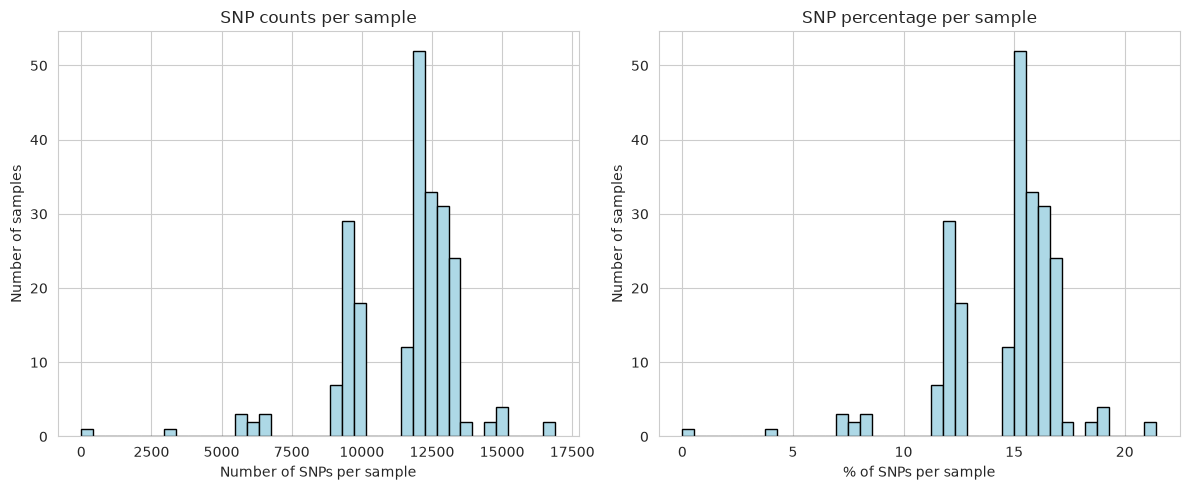

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SNPs per sample')
axes[0].set_ylabel('Number of samples')
axes[0].set_title('SNP counts per sample')

axes[1].hist(percentage, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SNPs per sample')
axes[1].set_ylabel('Number of samples')
axes[1].set_title('SNP percentage per sample')

plt.tight_layout()
plt.savefig('Figures/01_SNPs_per_sample.png', dpi=300, bbox_inches='tight')
plt.show()

We see that at least one sample do not have any SNPs at all! Since this represents very few samples, we can assume that they are simply very close to the reference strains (identical in terms of SNPs) and keep them in the analysis.

Otherwise, we see that there is variation in the total number of SNPs and percentage of SNPs for each sample. Interestingly, there seems to be some clustering happening (with for instance little samples having around 11000 SNPs (or 13-14% SNPs). This could very well reflect biology, with each "cluster" we see on the graph representing a different bacterial lineage (SNPs are often inherited together). 

### **3.2 SNPs per region**
Let's now visualize the total number and percentage of SNPs for each genomic region (each feature).

In [15]:
counts_regions = snp_matrix.sum(axis=0)
percentage_regions = snp_matrix.mean(axis=0) * 100

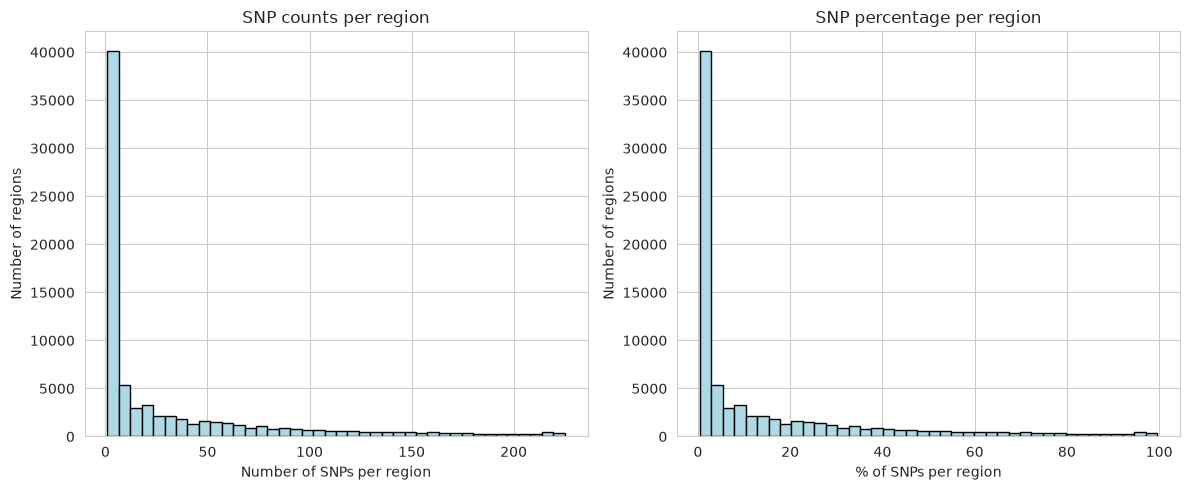

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(counts_regions, bins=40, color='lightblue', edgecolor='black')
axes[0].set_xlabel('Number of SNPs per region')
axes[0].set_ylabel('Number of regions')
axes[0].set_title('SNP counts per region')

axes[1].hist(percentage_regions, bins=40, color='lightblue', edgecolor='black')
axes[1].set_xlabel('% of SNPs per region')
axes[1].set_ylabel('Number of regions')
axes[1].set_title('SNP percentage per region')

plt.tight_layout()
plt.savefig('Figures/01_SNPs_per_feature.png', dpi=300, bbox_inches='tight')
plt.show()

Here, we directly see that a lot of regions actually contain either 0% or 100% of SNPs. We will need to remove these features from the analysis, as they do not contain any information for a machine learning model. I could already perform this step here, but I choose to first split the data set into training and test sets, and then remove any features that are invariant in the training data.

### **3.3 Clustering**
Let's see how the samples ressemble each other and if some already cluster together based on their SNPs. We can do this by computing a pairwise SNP distance matrix (using the Hamming distance between samples). The Hamming distance is the total number of SNP positions at which two samples differ.
Once we have calculated this, we can cluster and visualize using seaborn's *clustermap* function. 

#### **A note on clustering and trees**
Note that a similar analysis is already performed in the snakemake pipeline itself to generate a phylogenetic tree. I will quickly explain how the two methods to generate the trees differ.
Here, we are using the **Hamming distance** and counting the **total number of different SNPs** between strains. The tree is the built using hierarchical agglomerative clustering. This algorithm simply compares every sample pair, and counts how many positions differ. A dendogram (or tree) is then built by hierarchical agglomerative clustering (Start with every strain in its own cluster, find the two closest clusters and merge them, recompute the distances between the new cluster and all the others, and repeat until everything is merged into a single cluster). This method is good for quick visualisations, but also shows some limitations. For instance, when using the Hamming distance, all differences count the same and the model for instance doesn't take into account that some mutations may happen more easily than others. Also, if a position mutated twice, it will look unchanged. In this case, distances between distant samples can be underestimated. Finally, it doesn't look at the base at all, only if a SNP is present or absent.

In the Snakemake pipeline, we are directly using the multi-sample **DNA alignement**, and using the software **IQTree** to generate the most probable tree that best explains this alignement. IQTree builds trees based on a model of how DNA changes over time. 

In [17]:
X = snp_matrix.values
dist = X @ (1 - X).T + (1 - X) @ X.T
dist_df = pd.DataFrame(dist, index=snp_matrix.index, columns=snp_matrix.index)

In [18]:
Z = linkage(squareform(dist_df.values, checks=False), method="average")

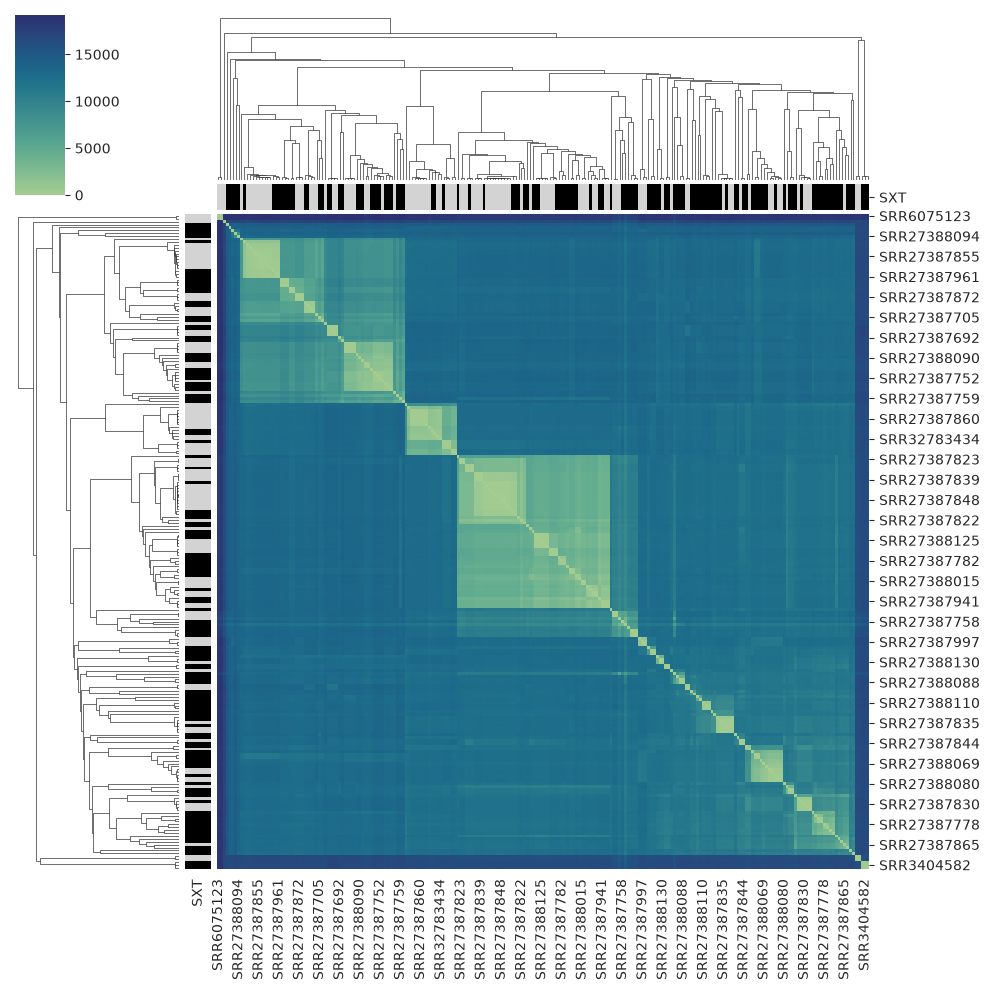

In [19]:
palette = {0: "lightgrey", 1: "black"}
strain_colors = SXT_profile.map(palette).rename("SXT")

sns.clustermap(dist_df, cmap="crest", row_linkage=Z, col_linkage=Z, row_colors=strain_colors, col_colors=strain_colors)

plt.savefig('Figures/01_Clustering.png', dpi=600, bbox_inches='tight')
plt.show()

This is an interesting graph. We see that there do seem to be some clusters of strains that exhibit similar resistance profiles, but that overall, as we saw using the phylogenetic tree built by IQ-Tree, it looks like the resistances are well distributed over this tree. This is important information, as this makes it more likely that the model will really learn to predict resistances and not simply "lineages". 

## **4. Save preprocessed data**
Let's save the preprocessed data.

In [ ]:
# Save cleaned CNV matrix
snp_matrix.to_csv('Data/snps_cleaned.csv')

# Save SXT resistance profile
SXT_profile.to_csv('Data/SXT_cleaned.csv', header=['SXT_binary'])

print(f'Shape: {snp_matrix.shape}')